# 01 · Raw count characteristics

Before any curation step can be judged, you need to know what the raw matrix
looks like. This notebook measures the properties that every later method is
reacting to:

1. **Depth** – how many molecules and genes each cell yields
2. **Count noise** – how variance and zeros relate to the mean
3. **Confounders** – how much variation is technical (batch, donor, depth)
   rather than biological (cell type)
4. **Simulator knobs** – what each synthetic effect does when turned up or off

Every notebook in this folder starts from the same loader. Leave
`DATA_PATH = None` for the synthetic simulator, or point it at an `.h5ad`
file to run the identical analysis on real data.

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from nbutils import (set_style, load_data, describe, pca, r2_by_group, codes,
                     SERIES, BLUE, ORANGE, AQUA, YELLOW, NEUTRAL, MUTED, SURFACE, INK)
from src.data.preprocessing import normalize_counts, is_raw_counts

set_style()

In [2]:
# --- data switch ----------------------------------------------------------
DATA_PATH = None        # e.g. "/path/to/dataset.h5ad"
OBS_MAP   = None        # e.g. {"donor": "donor_id", "sample": "batch_id"}
RAW_LAYER = None        # e.g. "counts" when .X holds normalized values

adata = load_data(DATA_PATH, OBS_MAP, RAW_LAYER, n_cells=3000, n_genes=2000, seed=0)
IS_SYNTHETIC = bool(adata.uns.get("synthetic", False))

X = sp.csr_matrix(adata.X)
obs = adata.obs
print("synthetic:", IS_SYNTHETIC, "| raw integer counts:", is_raw_counts(X))
pd.DataFrame([describe(X, "raw")]).set_index("stage")

synthetic: True | raw integer counts: True


,cells,genes,sparsity_%,median_depth,median_genes_per_cell
stage,,,,,
raw,3000,2000,86.8,5538.5,259


## 1 · Depth

Library size (total UMIs per cell) is the dominant technical axis in any
droplet dataset. It usually spans about an order of magnitude, and the number
of genes detected rises with it. That coupling is why normalization exists:
without it, "deeply sequenced" looks like a cell type.

library size spans 38x (5th–95th percentile: 2087–13708)
Spearman(depth, genes detected) = 0.96


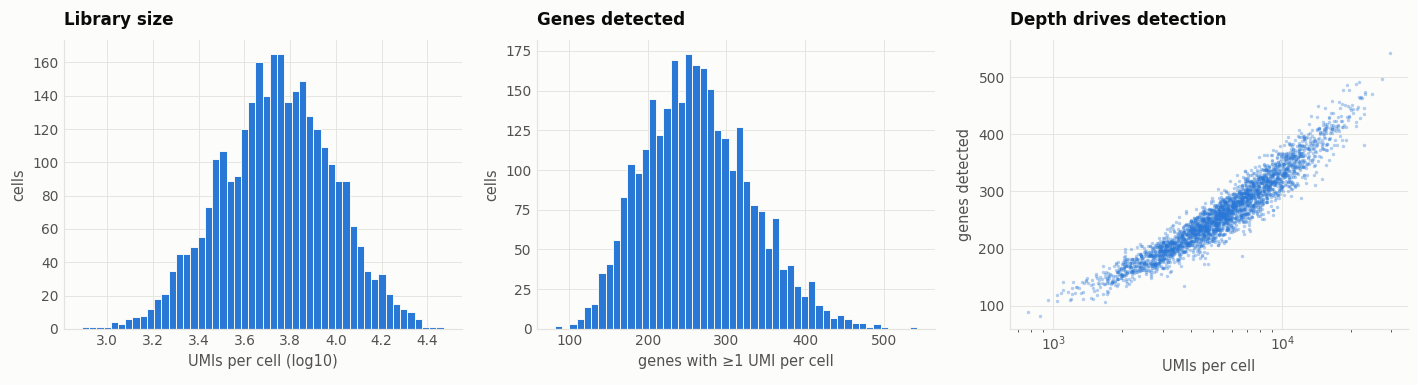

In [3]:
lib = np.asarray(X.sum(1)).ravel()
n_genes_cell = np.diff(X.indptr)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(np.log10(lib), bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax[0].set(title="Library size", xlabel="UMIs per cell (log10)", ylabel="cells")
ax[1].hist(n_genes_cell, bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax[1].set(title="Genes detected", xlabel="genes with ≥1 UMI per cell", ylabel="cells")
ax[2].scatter(lib, n_genes_cell, s=5, color=BLUE, alpha=0.35, linewidths=0)
ax[2].set(title="Depth drives detection", xscale="log",
          xlabel="UMIs per cell", ylabel="genes detected")
fig.tight_layout()

print(f"library size spans {lib.max() / max(lib.min(), 1):.0f}x "
      f"(5th–95th percentile: {np.percentile(lib, 5):.0f}–{np.percentile(lib, 95):.0f})")
print(f"Spearman(depth, genes detected) = "
      f"{pd.Series(lib).corr(pd.Series(n_genes_cell), method='spearman'):.2f}")

## 2 · Count noise: variance and zeros

Two questions decide which likelihood and which normalization are defensible.

**Is the variance Poisson?** If it were, every gene would sit on the
`variance = mean` line. UMI data sits above it, and the excess grows with the
mean, which is the negative-binomial signature `var = mean + φ·mean²`.

**Are there "too many" zeros?** The common belief is that droplet data is
zero-inflated by technical dropout. The test is whether the observed zero
fraction of each gene exceeds what a negative binomial with that gene's mean
and dispersion already predicts.

The dispersion here is estimated across all cells, so it absorbs depth and
cell-type differences as well as sampling noise. It is an upper bound on the
technical dispersion, not an estimate of it.

median variance / mean ratio (genes with mean > 0.1): 3.62  (Poisson = 1)
mean |observed − Poisson| zero fraction: 0.060
mean |observed − NB|      zero fraction: 0.005
genes with >5 points more zeros than NB predicts: 0.1%


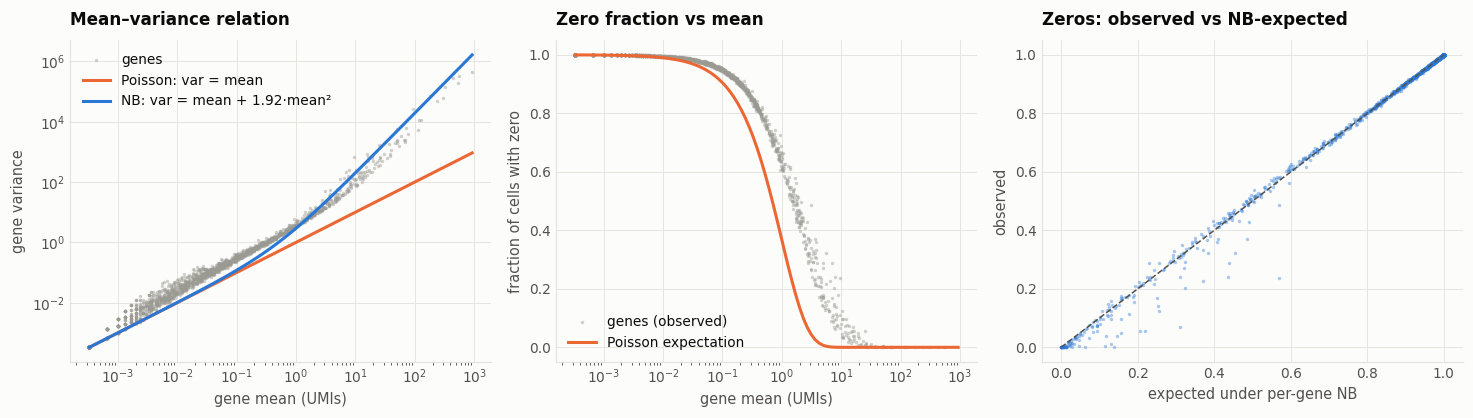

In [4]:
mu = np.asarray(X.mean(0)).ravel()
var = np.asarray(X.multiply(X).mean(0)).ravel() - mu ** 2
expressed = mu > 0
phi_gene = np.clip((var - mu) / np.maximum(mu, 1e-12) ** 2, 1e-8, None)   # method of moments
phi = float(np.median(phi_gene[mu > 0.5])) if (mu > 0.5).any() else float(np.median(phi_gene[expressed]))
grid = np.logspace(np.log10(mu[expressed].min()), np.log10(mu.max()), 100)

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.9))
ax[0].scatter(mu[expressed], var[expressed], s=5, color=NEUTRAL, alpha=0.45, linewidths=0, label="genes")
ax[0].plot(grid, grid, color=ORANGE, label="Poisson: var = mean")
ax[0].plot(grid, grid + phi * grid ** 2, color=BLUE, label=f"NB: var = mean + {phi:.2f}·mean²")
ax[0].set(xscale="log", yscale="log", title="Mean–variance relation",
          xlabel="gene mean (UMIs)", ylabel="gene variance")
ax[0].legend(loc="upper left")

zero_obs = 1 - np.diff(X.tocsc().indptr) / X.shape[0]
zero_pois = np.exp(-mu)
zero_nb = (1 + phi_gene * mu) ** (-1 / phi_gene)

ax[1].scatter(mu[expressed], zero_obs[expressed], s=5, color=NEUTRAL, alpha=0.45, linewidths=0, label="genes (observed)")
ax[1].plot(grid, np.exp(-grid), color=ORANGE, label="Poisson expectation")
ax[1].set(xscale="log", title="Zero fraction vs mean",
          xlabel="gene mean (UMIs)", ylabel="fraction of cells with zero")
ax[1].legend(loc="lower left")

ax[2].scatter(zero_nb[expressed], zero_obs[expressed], s=5, color=BLUE, alpha=0.4, linewidths=0)
ax[2].plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
ax[2].set(title="Zeros: observed vs NB-expected",
          xlabel="expected under per-gene NB", ylabel="observed")
fig.tight_layout()

excess = zero_obs[expressed] - zero_nb[expressed]
print(f"median variance / mean ratio (genes with mean > 0.1): {np.median((var / np.maximum(mu, 1e-12))[mu > 0.1]):.2f}  (Poisson = 1)")
print(f"mean |observed − Poisson| zero fraction: {np.abs(zero_obs - zero_pois)[expressed].mean():.3f}")
print(f"mean |observed − NB|      zero fraction: {np.abs(excess).mean():.3f}")
print(f"genes with >5 points more zeros than NB predicts: {(excess > 0.05).mean():.1%}")

**Reading it.** Points above the orange line in the left panel are
overdispersed. In the right panel, points on the diagonal are genes whose
zeros a plain negative binomial already accounts for; points clearly *above*
it would be evidence for zero inflation. This is the measurement behind the
repo's default of a plain-NB likelihood (`ZINBDecoderHead(zero_inflated=False)`).
Rerun it on your own data before changing that default.

## 3 · Confounders: what the leading axes of variation encode

Take the standard log-normalized PCA and ask, for each principal component,
how much of its variance each covariate explains. Biology you want should
load on cell type. Anything loading on batch, donor or depth is technical
structure that a model can learn instead of biology.

When donors are nested inside batches (each donor processed in one batch),
the donor and batch lines nearly coincide: the two cannot be told apart from
this view alone.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
cell type,0.14,0.17,0.14,0.45,0.34,0.50,0.52,0.54,0.44,0.08
batch,0.37,0.85,0.82,0.45,0.27,0.20,0.01,0.00,0.02,0.04
donor,0.39,0.85,0.82,0.45,0.27,0.21,0.02,0.00,0.02,0.07
depth,0.52,0.41,0.05,0.00,0.01,0.00,0.03,0.00,0.01,0.21


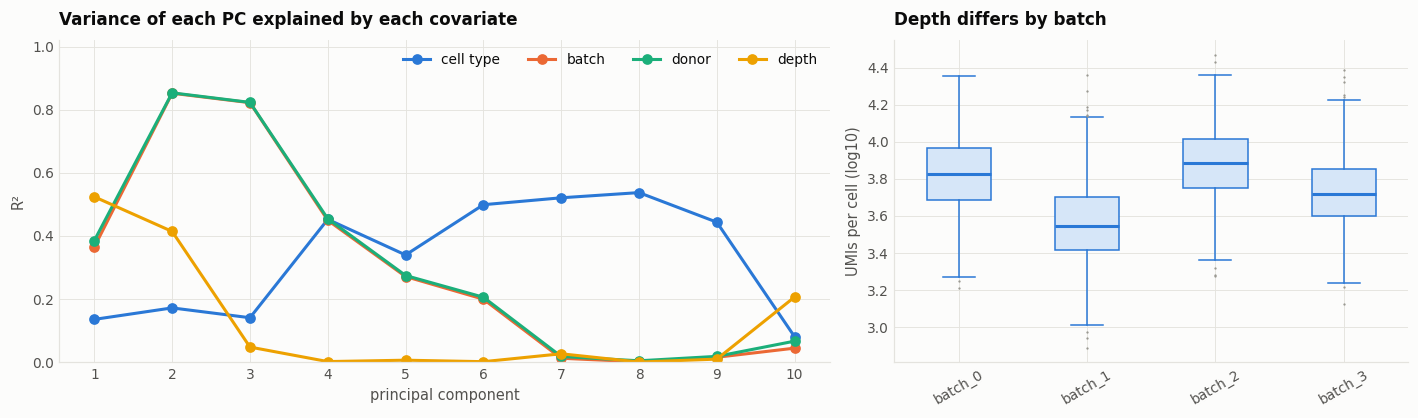

In [5]:
Xn, _ = normalize_counts(X)
Z = pca(Xn, k=10)

covariates = {"cell type": obs["cell_type"], "batch": obs["batch_id"], "donor": obs["donor_id"]}
r2 = {name: r2_by_group(Z, values) for name, values in covariates.items()}
r2["depth"] = np.array([np.corrcoef(Z[:, i], np.log(lib))[0, 1] ** 2 for i in range(Z.shape[1])])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
pcs = np.arange(1, Z.shape[1] + 1)
for (name, vals), color in zip(r2.items(), SERIES):
    ax[0].plot(pcs, vals, marker="o", color=color, label=name)
ax[0].set(title="Variance of each PC explained by each covariate",
          xlabel="principal component", ylabel="R²", xticks=pcs, ylim=(0, 1.02))
ax[0].legend(ncol=4, loc="upper right")

batches = sorted(obs["batch_id"].astype(str).unique())
ax[1].boxplot([np.log10(lib[(obs["batch_id"].astype(str) == b).to_numpy()]) for b in batches],
              tick_labels=batches, widths=0.5, patch_artist=True,
              boxprops=dict(facecolor="#d6e6f8", edgecolor=BLUE),
              medianprops=dict(color=BLUE, linewidth=2),
              whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
              flierprops=dict(marker=".", markersize=3, markerfacecolor=NEUTRAL, markeredgecolor="none"))
ax[1].set(title="Depth differs by batch", ylabel="UMIs per cell (log10)")
ax[1].tick_params(axis="x", rotation=30)
fig.tight_layout()

pd.DataFrame(r2, index=[f"PC{i}" for i in pcs]).round(2).T

Batches also differ in *which cells they contain*. When composition is
confounded with batch, "remove everything batch-predictive" also removes real
biology, which is why batch correction cannot be evaluated by mixing metrics
alone.

cell_type,celltype_00,celltype_01,celltype_02,celltype_03,celltype_04,celltype_05,celltype_06,celltype_07
batch_id,,,,,,,,
batch_0,0.06,0.06,0.09,0.08,0.21,0.17,0.28,0.05
batch_1,0.03,0.06,0.31,0.20,0.16,0.10,0.11,0.03
batch_2,0.21,0.16,0.08,0.09,0.17,0.10,0.12,0.07
batch_3,0.07,0.28,0.11,0.09,0.19,0.07,0.16,0.04


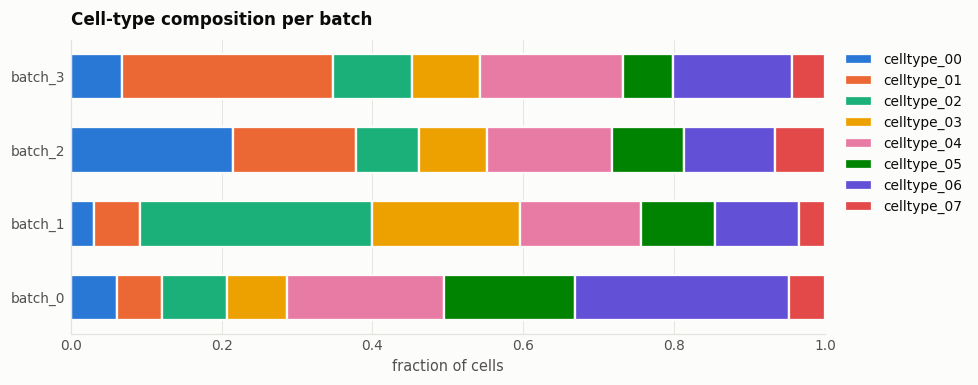

In [6]:
comp = (obs.groupby("batch_id", observed=True)["cell_type"]
           .value_counts(normalize=True).unstack(fill_value=0))
comp = comp[sorted(comp.columns)]

fig, ax = plt.subplots(figsize=(9, 3.6))
left = np.zeros(len(comp))
for i, ct in enumerate(comp.columns[:8]):
    ax.barh(comp.index.astype(str), comp[ct], left=left, color=SERIES[i],
            edgecolor=SURFACE, linewidth=1.5, height=0.62, label=ct)
    left += comp[ct].to_numpy()
if comp.shape[1] > 8:      # never generate a ninth hue: fold the tail
    rest = comp.iloc[:, 8:].sum(1)
    ax.barh(comp.index.astype(str), rest, left=left, color=NEUTRAL,
            edgecolor=SURFACE, linewidth=1.5, height=0.62, label="other")
ax.set(title="Cell-type composition per batch", xlabel="fraction of cells", xlim=(0, 1))
ax.grid(axis="y", visible=False)
ax.legend(ncol=1, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
comp.round(2)

## 4 · Simulator knobs (synthetic data only)

The simulator's value is that each effect can be switched off, so you can
check that a measurement responds to the thing it claims to measure. The
three sweeps below vary one knob at a time.

- **Batch effect** – per-gene multiplicative shifts per batch. Tracked with
  principal-component regression on batch. The second line also turns off
  the donor effect, the per-batch depth shift and the composition shift,
  showing how much "batch" signal comes from those rather than from the
  batch effect itself.
- **Ambient RNA** – a share of each cell's counts drawn from a pooled
  profile. It barely moves sparsity (the pooled profile is dominated by
  genes that are already detected) but it steadily dilutes cell-type signal.
- **Doublets** – two cells in one droplet, visible as a depth shift.

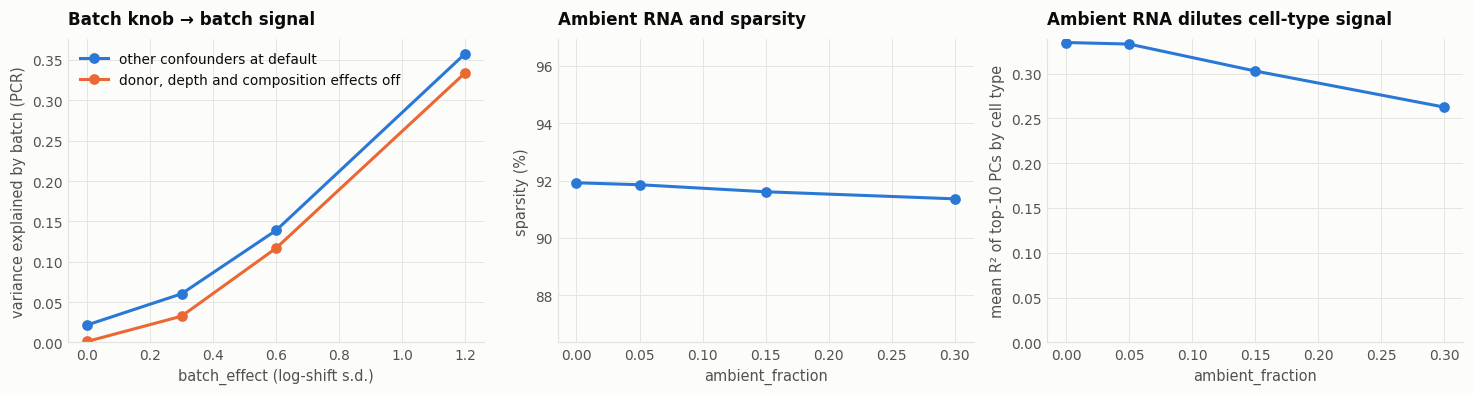

In [7]:
if IS_SYNTHETIC:
    from src.eval.metrics import pcr_batch

    def summarize(**knobs):
        a = load_data(n_cells=1500, n_genes=1000, seed=1, **knobs)
        Xa = sp.csr_matrix(a.X)
        Za = pca(normalize_counts(Xa)[0], k=20)
        return {
            "pcr_batch": pcr_batch(Za, a.obs["batch_id"]),
            "celltype_r2": float(r2_by_group(Za[:, :10], a.obs["cell_type"]).mean()),
            "sparsity": 1 - Xa.nnz / (Xa.shape[0] * Xa.shape[1]),
        }

    levels_b = [0.0, 0.3, 0.6, 1.2]
    others_on = [summarize(batch_effect=b) for b in levels_b]
    others_off = [summarize(batch_effect=b, donor_effect=0.0, batch_library_effect=0.0,
                            composition_shift=0.0) for b in levels_b]
    levels_a = [0.0, 0.05, 0.15, 0.3]
    amb = [summarize(ambient_fraction=a, ambient_sd=0.0) for a in levels_a]

    fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.7))
    ax[0].plot(levels_b, [r["pcr_batch"] for r in others_on], marker="o", color=BLUE,
               label="other confounders at default")
    ax[0].plot(levels_b, [r["pcr_batch"] for r in others_off], marker="o", color=ORANGE,
               label="donor, depth and composition effects off")
    ax[0].set(title="Batch knob → batch signal", xlabel="batch_effect (log-shift s.d.)",
              ylabel="variance explained by batch (PCR)", ylim=(0, None))
    ax[0].legend(loc="upper left")

    ax[1].plot(levels_a, [100 * r["sparsity"] for r in amb], marker="o", color=BLUE)
    sp_vals = [100 * r["sparsity"] for r in amb]
    ax[1].set(title="Ambient RNA and sparsity", xlabel="ambient_fraction",
              ylabel="sparsity (%)", ylim=(min(sp_vals) - 5, min(100, max(sp_vals) + 5)))
    ax[2].plot(levels_a, [r["celltype_r2"] for r in amb], marker="o", color=BLUE)
    ax[2].set(title="Ambient RNA dilutes cell-type signal", xlabel="ambient_fraction",
              ylabel="mean R² of top-10 PCs by cell type", ylim=(0, None))
    fig.tight_layout()
else:
    print("Real data loaded: simulator sweeps skipped.")

median depth: singlets 5359, doublets 11734 (2.19x)


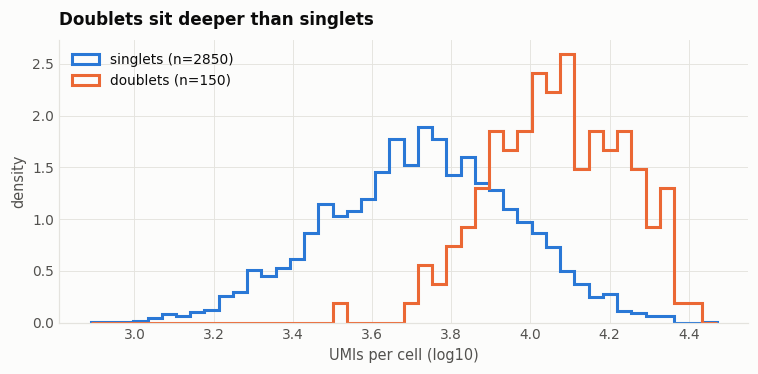

In [8]:
if IS_SYNTHETIC and "is_doublet" in obs:
    d = obs["is_doublet"].to_numpy()
    bins = np.linspace(np.log10(lib).min(), np.log10(lib).max(), 45)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(np.log10(lib[~d]), bins=bins, density=True, histtype="step", linewidth=2,
            color=BLUE, label=f"singlets (n={(~d).sum()})")
    ax.hist(np.log10(lib[d]), bins=bins, density=True, histtype="step", linewidth=2,
            color=ORANGE, label=f"doublets (n={d.sum()})")
    ax.set(title="Doublets sit deeper than singlets", xlabel="UMIs per cell (log10)", ylabel="density")
    ax.legend()
    fig.tight_layout()
    print(f"median depth: singlets {np.median(lib[~d]):.0f}, doublets {np.median(lib[d]):.0f} "
          f"({np.median(lib[d]) / np.median(lib[~d]):.2f}x)")

## What to carry forward

- Depth varies widely and drives gene detection → **02** measures what
  normalization does about it.
- Variance is overdispersed and zeros track the negative binomial → the
  likelihood choice in the model heads.
- Leading PCs carry batch, donor and depth signal alongside cell type →
  **02** (batch-aware gene selection) and **03** (splitting by donor).
- The values in this notebook come from whichever dataset is loaded above.
  On synthetic data they describe the simulator, not biology.